# Ejercicio Regression Tree
Son datos de temperaturas tomados de la ciudad de Seattle. El objetivo es intentar predecir lo mejor posible la máxima temperatura (columna `actual`) que alcanzaremos al día siguiente. Para ello contaremos con temperaturas de los dos días anteriores, históricos de máximas temperaturas y un amigo bastante chapas que te da su predicción del tiempo cada día.

**Resumen de datos**:
* year: 2016 for all data points
* month: number for month of the year
* day: number for day of the year
* week: day of the week as a character string
* temp_2: max temperature 2 days prior
* temp_1: max temperature 1 day prior
* average: historical average max temperature
* actual: max temperature measurement
* friend: your friend’s prediction, a random number between 20 below the average and 20 above the average


### 1. Importa el csv "temps.csv"

In [2]:
import pandas as pd
import numpy as np
import os
import sklearn
import matplotlib as mpl
import matplotlib.pyplot as plt

df = pd.read_csv("data/temps.csv")

### 2. Realiza un análisis exploratorio junto con un Feature Engineering

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 348 entries, 0 to 347
Data columns (total 9 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   year     348 non-null    int64  
 1   month    348 non-null    int64  
 2   day      348 non-null    int64  
 3   week     348 non-null    str    
 4   temp_2   348 non-null    int64  
 5   temp_1   348 non-null    int64  
 6   average  348 non-null    float64
 7   actual   348 non-null    int64  
 8   friend   348 non-null    int64  
dtypes: float64(1), int64(7), str(1)
memory usage: 24.6 KB


In [3]:
df.head()

,year,month,day,week,temp_2,temp_1,average,actual,friend
0,2016,1,1,Fri,45,45,45.6,45,29
1,2016,1,2,Sat,44,45,45.7,44,61
2,2016,1,3,Sun,45,44,45.8,41,56
3,2016,1,4,Mon,44,41,45.9,40,53
4,2016,1,5,Tues,41,40,46.0,44,41


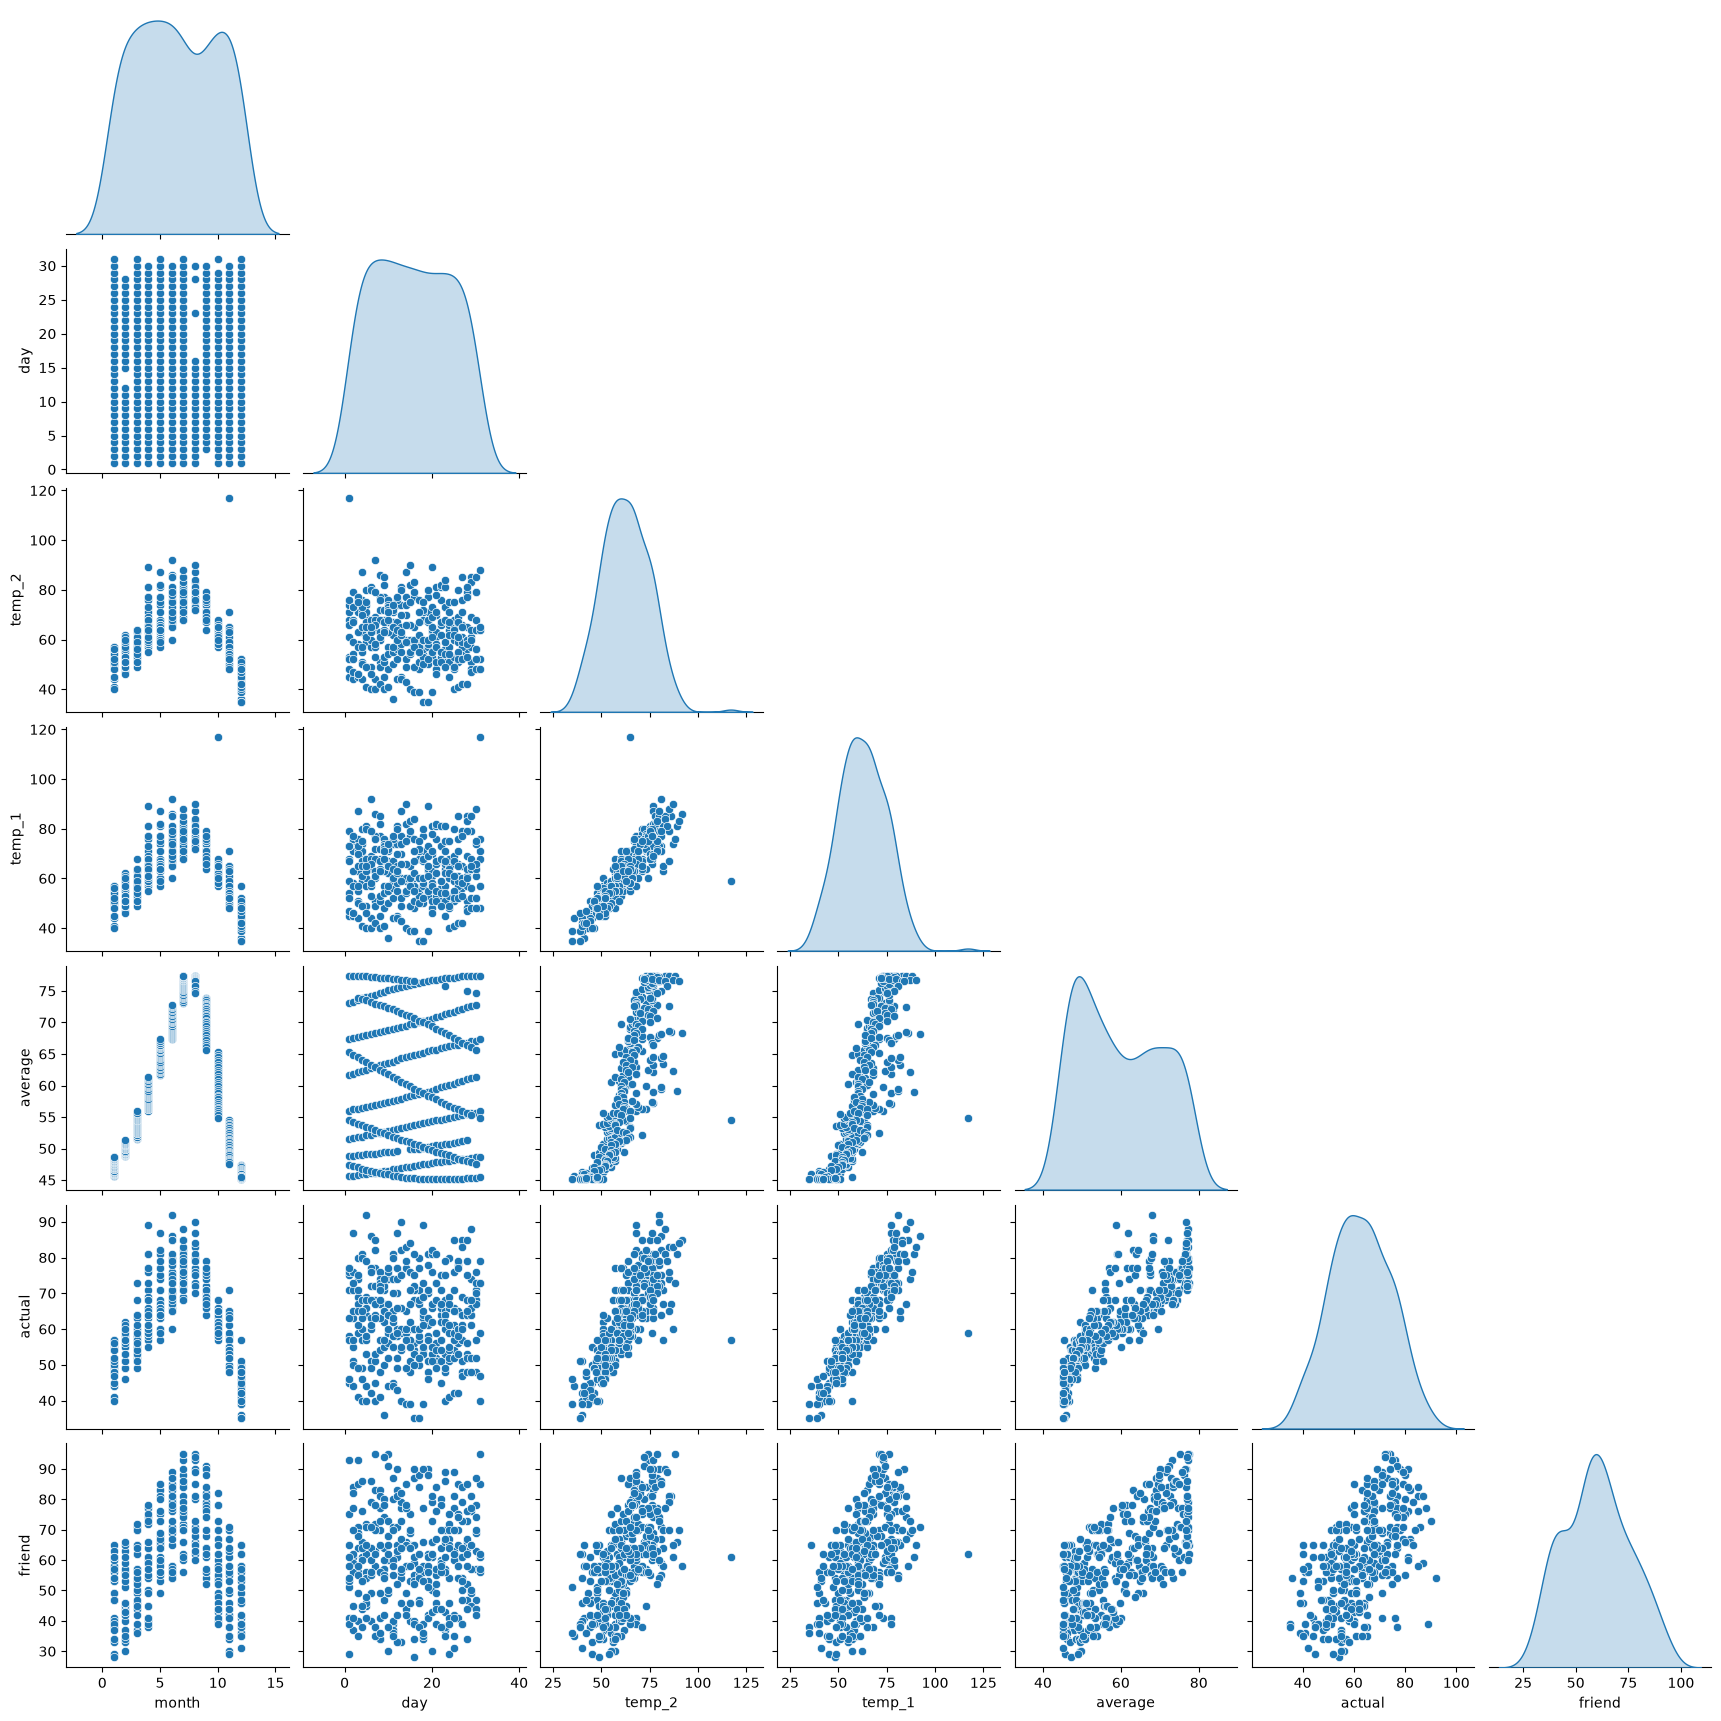

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(df[["month", "day", "temp_2", "temp_1", "average", "actual", "friend"]],
             corner=True,
             diag_kind="kde")

plt.show()

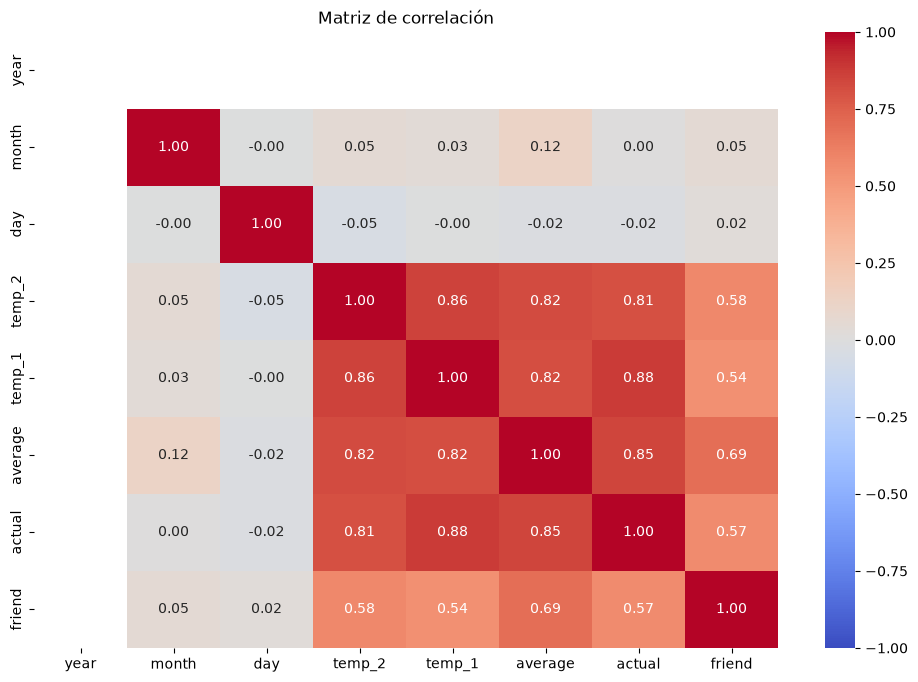

In [13]:
plt.figure(figsize=(12, 8))

sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap="coolwarm",
            fmt=".2f",
            vmin=-1,
            vmax=1)

plt.title("Matriz de correlación")
plt.show()

In [14]:
df_fe = df.copy()
df_fe.drop(columns=["year", "week", "friend"], inplace=True)

In [19]:
df_fe["temp_mean"] = (df_fe["temp_1"] + df_fe["temp_2"]) / 2
df_fe["temp_dif"] = df_fe["temp_1"] - df_fe["temp_2"]

In [24]:
df_fe.drop(columns=["temp_diff"], inplace=True)

In [27]:
df_fe["temp_deviation"] = df_fe["temp_1"] - df_fe["average"]

In [28]:
df_fe.head()

,month,day,temp_2,temp_1,average,actual,temp_mean,temp_dif,temp_deviation
0,1,1,45,45,45.6,45,45.0,0,-0.6
1,1,2,44,45,45.7,44,44.5,1,-0.7
2,1,3,45,44,45.8,41,44.5,-1,-1.8
3,1,4,44,41,45.9,40,42.5,-3,-4.9
4,1,5,41,40,46.0,44,40.5,-1,-6.0


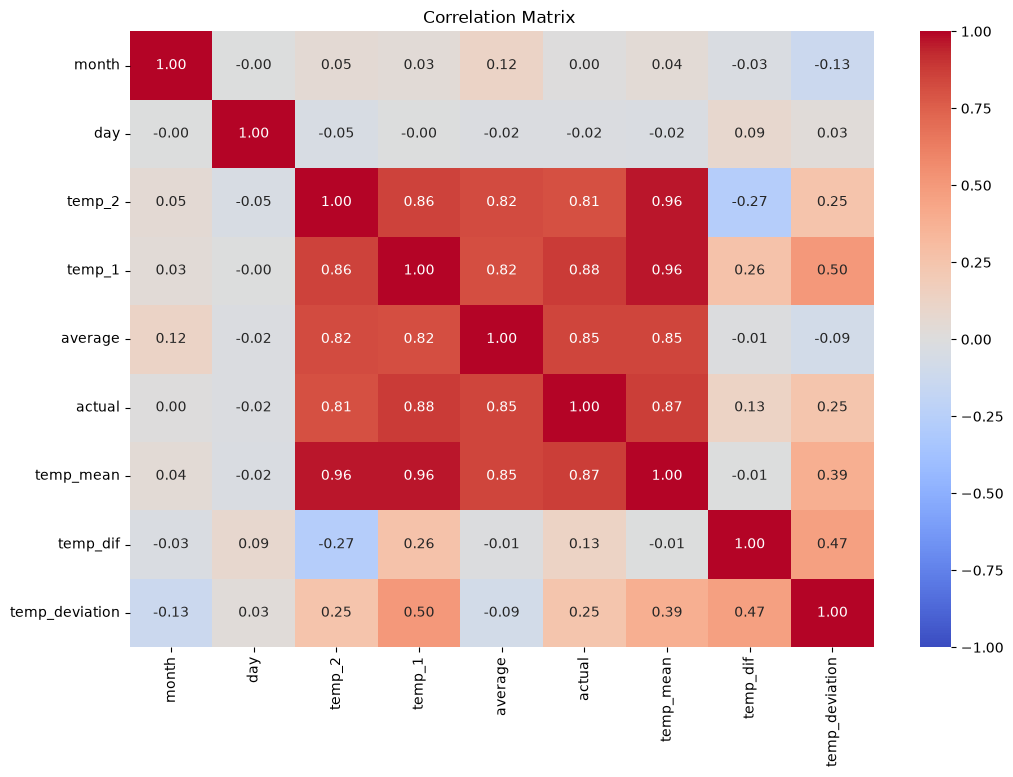

In [30]:
plt.figure(figsize=(12, 8))

sns.heatmap(df_fe.corr(),
            annot=True,
            cmap="coolwarm",
            fmt=".2f",
            vmin=-1,
            vmax=1)

plt.title("Correlation Matrix ")
plt.show()

In [31]:
X = df_fe.drop(columns=["actual"])
y = df_fe["actual"]


### 3. Selecciona variables y divide en train y test

In [35]:
from sklearn.model_selection import train_test_split

In [40]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

### 4. Entrena el modelo


In [38]:
from sklearn.ensemble import RandomForestRegressor

In [41]:
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [42]:
y_pred = model.predict(X_test)

### 5. Evaluación de tu modelo
Calcula el coeficiente de determinación. 

Calcula el MAE, MAPE, MSE y RMSE.

In [45]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2:", r2_score(y_test, y_pred))

MAE: 3.974000000000001
MSE: 28.171174285714283
RMSE: 5.307652426988252
R2: 0.6525438879995167


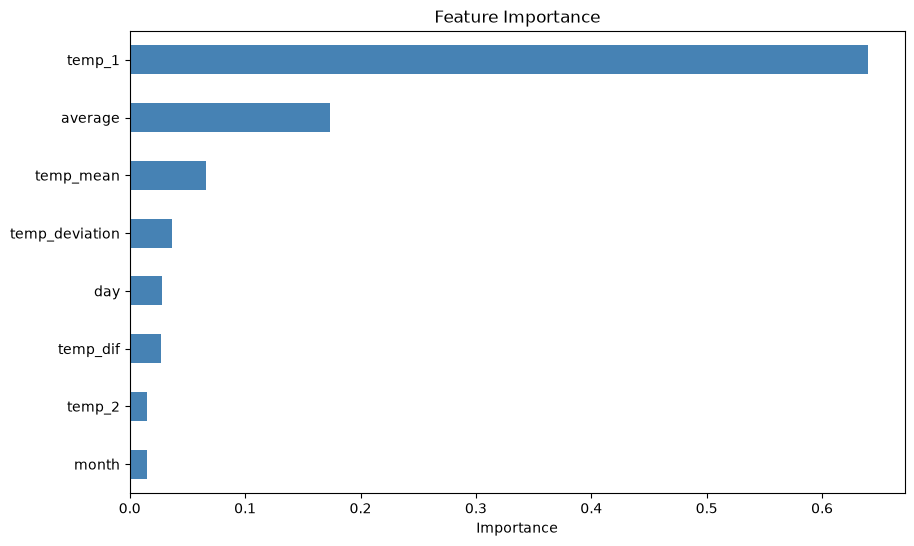

In [46]:
import pandas as pd

importance = pd.Series(model.feature_importances_, index=X_train.columns)

plt.figure(figsize=(10, 6))
importance.sort_values().plot(kind="barh", color="steelblue")

plt.title("Feature Importance")
plt.xlabel("Importance")
plt.show()

### 6. Representa el árbol de decisión

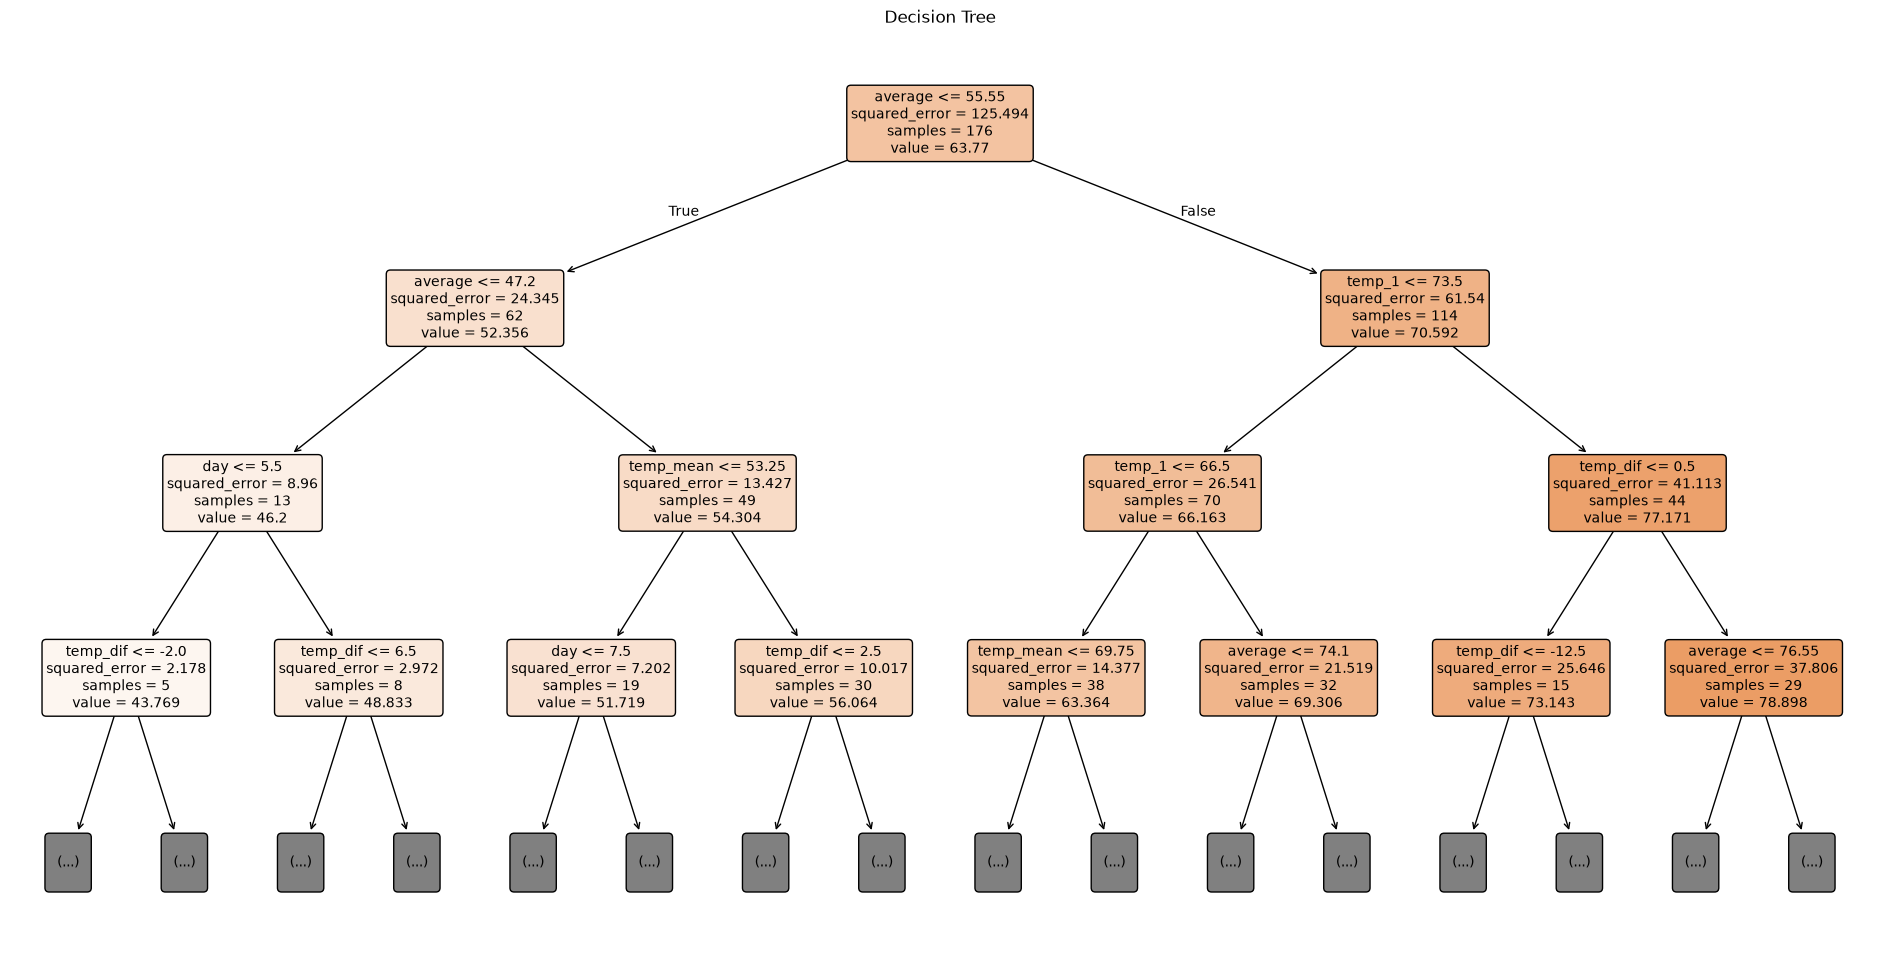

In [47]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(24, 12))

plot_tree(model.estimators_[0],
          feature_names=X_train.columns,
          filled=True,
          rounded=True,
          max_depth=3,
          fontsize=10)

plt.title("Decision Tree")
plt.show()

### 7. Modifica el max_depth a 3 y vuelve a entrenarlo

In [49]:
from sklearn.tree import DecisionTreeRegressor

In [51]:

model_tree = DecisionTreeRegressor(max_depth=3, random_state=42)

model_tree.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

In [52]:
y_pred_tree = model_tree.predict(X_test)

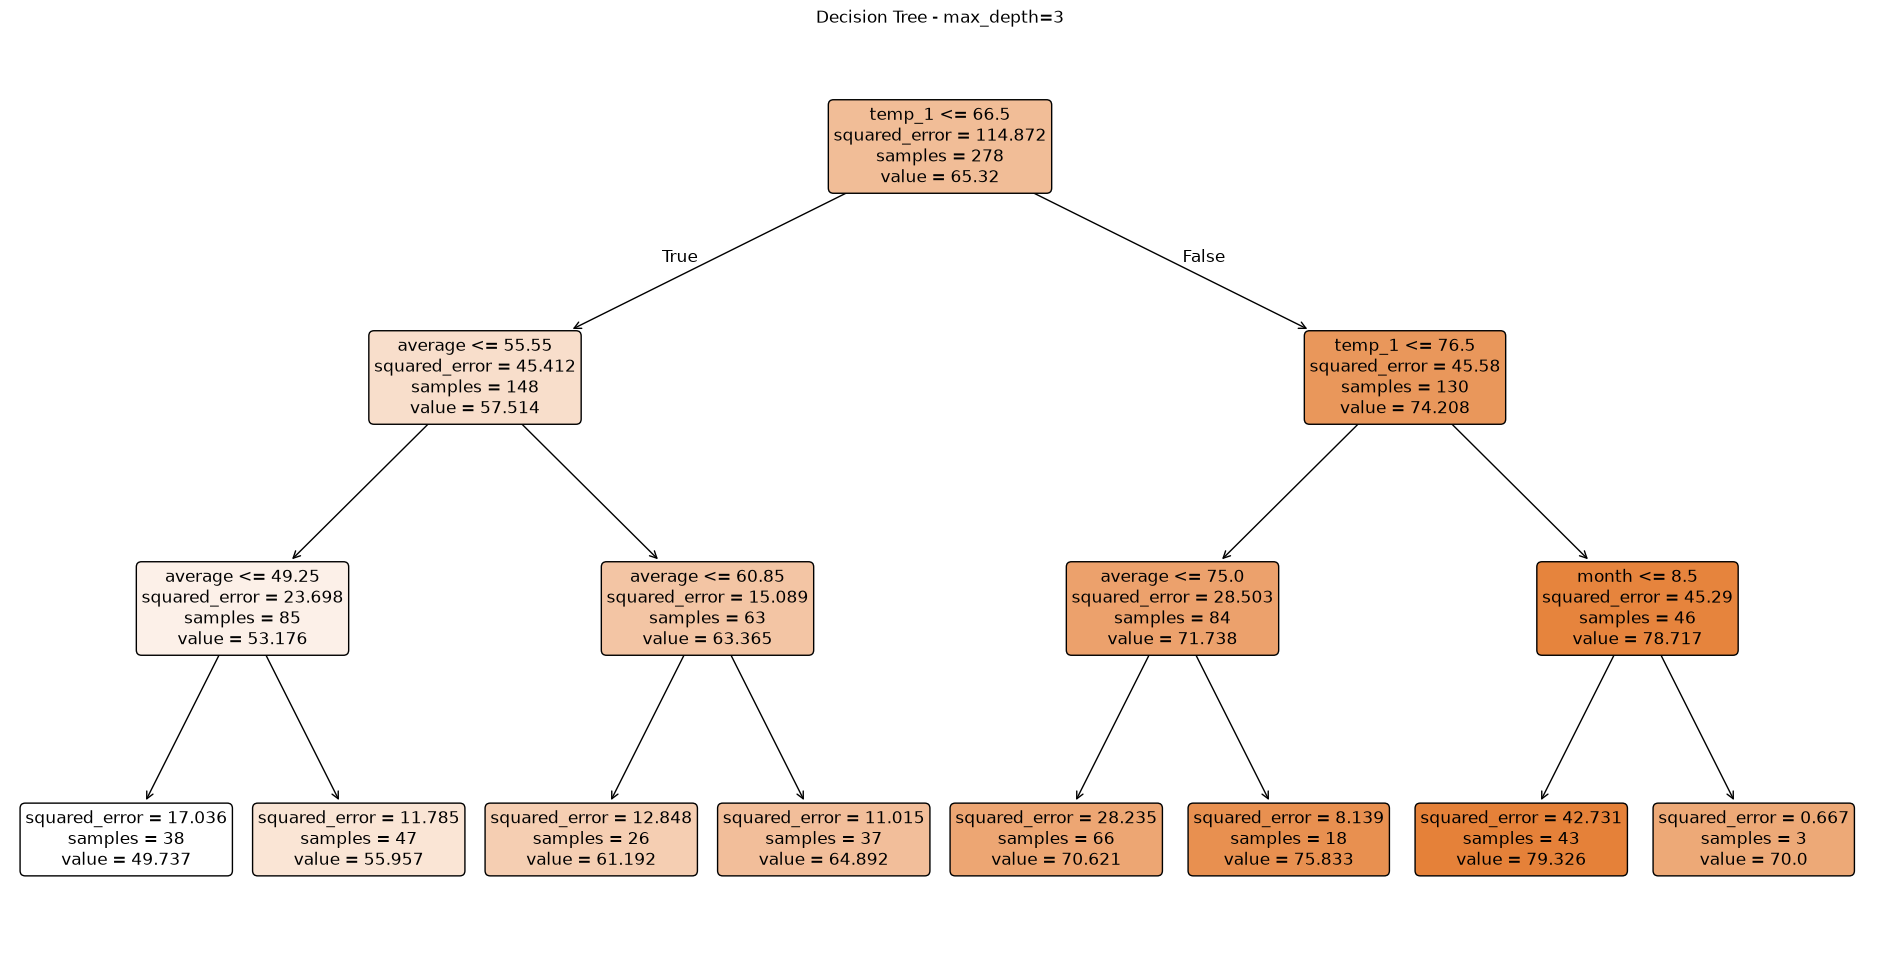

In [53]:
from sklearn.tree import plot_tree

plt.figure(figsize=(24, 12))

plot_tree(model_tree,
          feature_names=X_train.columns,
          filled=True,
          rounded=True)

plt.title("Decision Tree - max_depth=3")
plt.show()

### 8. Vuelve a evaluar tu modelo

In [55]:
print("MAE:", mean_absolute_error(y_test, y_pred_tree))
print("MSE:", mean_squared_error(y_test, y_pred_tree))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_tree)))
print("R2:", r2_score(y_test, y_pred_tree))

MAE: 5.173684396976671
MSE: 43.69276692270989
RMSE: 6.6100504478188284
R2: 0.461104504784289


### 9. Vuelve a representar su árbol

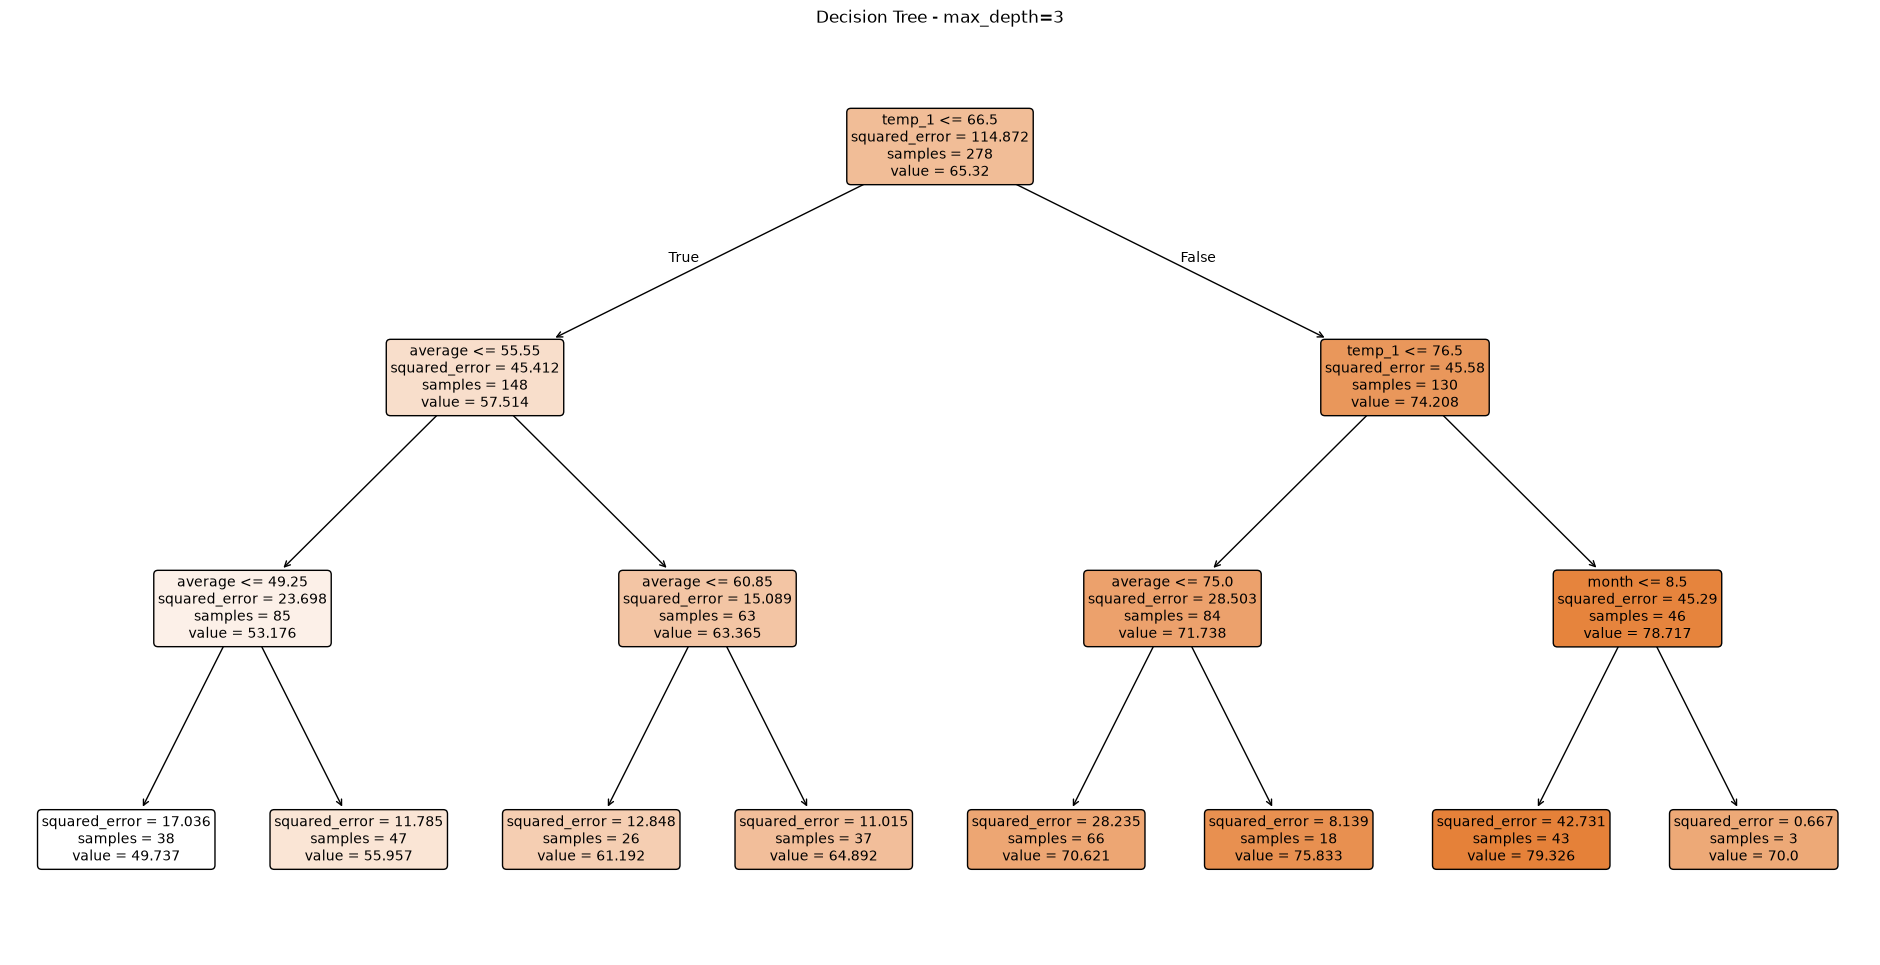

In [56]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(24, 12))

plot_tree(model_tree,
          feature_names=X_train.columns,
          filled=True,
          rounded=True,
          fontsize=10)

plt.title("Decision Tree - max_depth=3")
plt.show()

### 10. Utiliza un grid search con cross validation para hiperparametrizar tu modelo

In [57]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.tree import DecisionTreeRegressor

param_grid = {
    "max_depth": [2, 3, 5, 10, None],
    "min_samples_split": [2, 5, 10, 15],
    "min_samples_leaf": [1, 2, 4, 8],
    "criterion": ["squared_error", "absolute_error"]
}

In [58]:
cv = TimeSeriesSplit(n_splits=5)

grid_search = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['squared_error', 'absolute_error'], 'max_depth': [2, 3, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated sco

In [59]:
print("Mejores hiperparámetros:", grid_search.best_params_)
print("Mejor MAE en validación:", -grid_search.best_score_)

Mejores hiperparámetros: {'criterion': 'squared_error', 'max_depth': 10, 'min_samples_leaf': 8, 'min_samples_split': 2}
Mejor MAE en validación: 4.838795805643632


In [60]:
best_model = grid_search.best_estimator_

y_pred_grid = best_model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred_grid))
print("MSE:", mean_squared_error(y_test, y_pred_grid))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_grid)))
print("R2:", r2_score(y_test, y_pred_grid))

MAE: 4.158090441304727
MSE: 32.66890672402849
RMSE: 5.715672027332261
R2: 0.5970699979165041


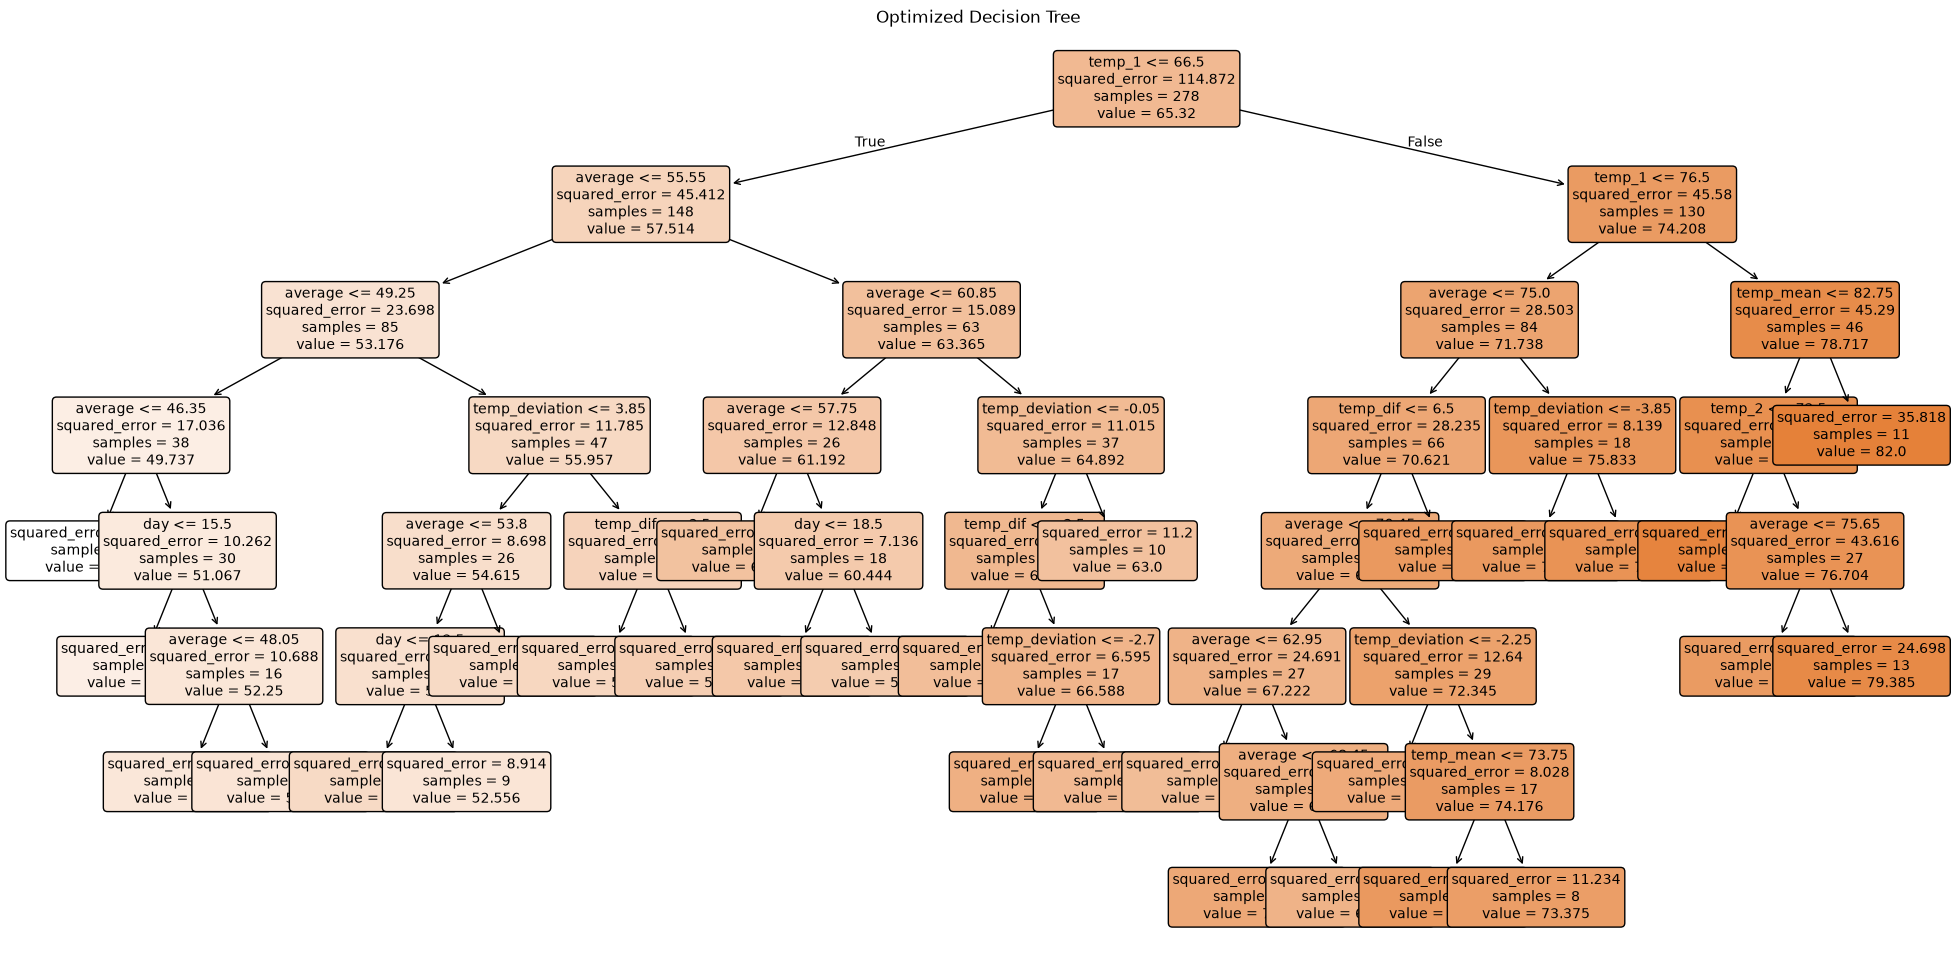

In [61]:
plt.figure(figsize=(24, 12))

plot_tree(best_model,
          feature_names=X_train.columns,
          filled=True,
          rounded=True,
          fontsize=10)

plt.title("Optimized Decision Tree")
plt.show()

In [62]:
import pandas as pd

resultados = pd.DataFrame({
    "Decision Tree (max_depth=3)": [
        mean_absolute_error(y_test, y_pred_tree),
        np.sqrt(mean_squared_error(y_test, y_pred_tree)),
        r2_score(y_test, y_pred_tree)
    ],
    "Decision Tree (Grid Search)": [
        mean_absolute_error(y_test, y_pred_grid),
        np.sqrt(mean_squared_error(y_test, y_pred_grid)),
        r2_score(y_test, y_pred_grid)
    ]
}, index=["MAE", "RMSE", "R2"])

resultados

,Decision Tree (max_depth=3),Decision Tree (Grid Search)
MAE,5.173684,4.158090
RMSE,6.610050,5.715672
R2,0.461105,0.597070


### 11. Obten el `feature_importances` de cada variable en el último modelo

In [63]:
import pandas as pd

feature_importances = pd.Series(
    best_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

feature_importances

temp_1            0.743446
average           0.220924
temp_deviation    0.012113
temp_dif          0.010061
temp_mean         0.005933
temp_2            0.004084
day               0.003438
month             0.000000
dtype: float64

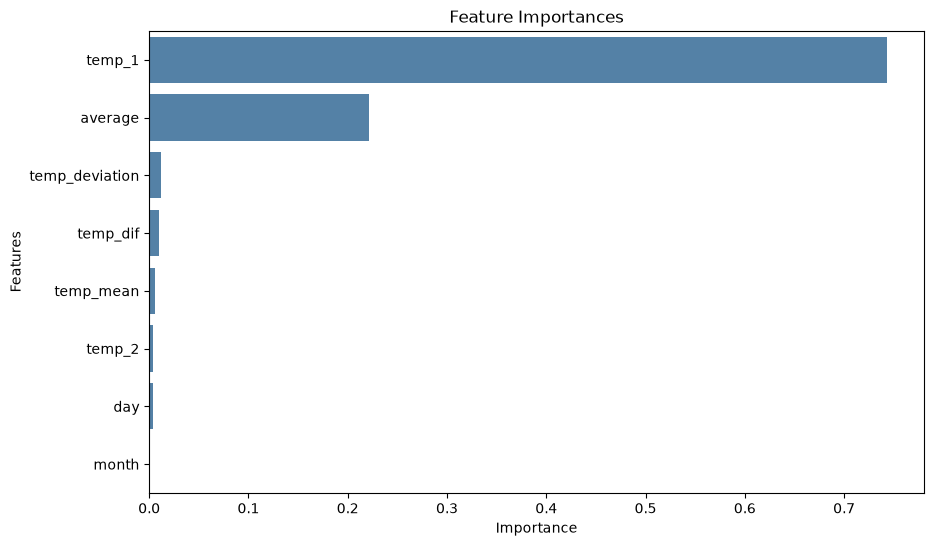

In [64]:
plt.figure(figsize=(10, 6))

sns.barplot(x=feature_importances.values,
            y=feature_importances.index,
            color="steelblue")

plt.title("Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()

### 12. Construye un nuevo modelo `DecisionTreeClassifier` que te clasifique cuando en un día va a hacer una temperatura mayor a 15ºC (59ºF). ¡Deberá tratarse como un problema de **clasificación**! Utiliza un grid search con cross validation y evalúa el mejor modelo.